# Learned reduced-order modeling: from a potential to a learned equation

This notebook develops the two figures proposed for the introductory LROM
section of the paper.  The example is elastic neutron scattering from
$^{40}\mathrm{Ca}$ at $E_{\rm lab}=14.1$ MeV with a real Woods--Saxon
interaction.  The potential depth $V_0$ and radius $R$ vary; the diffuseness
$a$ is fixed so that the geometry can be displayed directly.

The notebook deliberately separates two messages:

1. **Figure 1:** changing potentials generate a compressible manifold of
   wavefunctions, and MAXVOL selects a few informative potential locations;
2. **Figure 2:** the learned implicit equation reproduces the reduced
   coordinates and held-out wavefunctions across and beyond the training box.

All full-order solves, reduced bases, MAXVOL predictors, and learned implicit
equations are provided by the maintained `CleanCode/lrom` package.  The only
additional comparison is a transparent quadratic regression fitted directly
to the least-squares reduced coordinates.

## Mathematical structure

For the reduced radial wavefunction $\phi$,

$$
\left[\frac{d^2}{dr^2}+k^2-\frac{\ell(\ell+1)}{r^2}
-\frac{2\mu}{\hbar^2}V(r;\boldsymbol\omega)\right]\phi(r)=0,
$$

we construct the centered reduced representation

$$
\widehat\phi(r;\boldsymbol\omega)
=\phi_0(r)+\sum_{i=1}^{N_\phi}a_i(\boldsymbol\omega)\,\phi_i(r),
$$

where the modes $\phi_i$ are obtained from the SVD of centered full-order
snapshots.  Potential values at MAXVOL-selected locations are used as
predictors,

$$p_j(\boldsymbol\omega)=V(r_j;\boldsymbol\omega)-V(r_j;\boldsymbol\omega_0).$$

The LROM learns the implicit reduced equation

$$
\left[I+\sum_j \widetilde p_j M_j\right]a
=\sum_j \widetilde p_j c_j,
$$

with normalized predictors $\widetilde p_j$.  Inserting the least-squares
coordinates of every training snapshot makes the unknown entries of $M_j$ and
$c_j$ a single linear least-squares problem; no nonlinear training loop is
required.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

NOTEBOOK_DIR = Path.cwd().resolve()
candidates = [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents]
SOURCE_ROOT = next((p for p in candidates if (p / "lrom").is_dir()), None)
if SOURCE_ROOT is None:
    raise RuntimeError("Could not locate the repository root containing lrom/.")
sys.path.insert(0, str(SOURCE_ROOT))
sys.dont_write_bytecode = True

_matplotlib_config = tempfile.TemporaryDirectory(prefix="lrom-paper-mpl-")
os.environ["MPLCONFIGDIR"] = _matplotlib_config.name

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

import lrom
from lrom import BasisConfig, MaxVol, ScatteringLROM, ScatteringProblem
from lrom.physics import real_woods_saxon
from lrom.reduced import latin_hypercube
from lrom.diagnostics import relative_l2

assert Path(lrom.__file__).resolve().parent == SOURCE_ROOT / "lrom"

FIGURES = SOURCE_ROOT / "figures" / "draft_paper"
FIGURES.mkdir(exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 105,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 8.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

RAINBOW = plt.get_cmap("turbo")
METHOD_COLORS = {
    "LS": "#111111",
    "LROM": "#1565C0",
    "quadratic": "#D1495B",
}
SEED = 1204
BASIS_SIZE = 4
PREDICTOR_COUNT = 2

problem = ScatteringProblem(
    potential="real_woods_saxon",
    target_a=40,
    target_z=20,
    lab_energy=14.1,
    l_max=0,
    mesh_points=800,
    target_binding_energy=342.052184,
)
system = problem.system()
radius = system.radius
omega0 = np.array([46.7238, 4.0538, 0.6718])

def samples_from_rows(rows):
    return [
        {
            "Vv": float(row[0]),
            "Rv": float(row[1]),
            "av": float(row[2]),
            "E": 14.1,
            "A": 40,
            "Z": 20,
        }
        for row in np.asarray(rows)
    ]

def save_figure(fig, stem):
    fig.savefig(FIGURES / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    plt.show()

print(f"Using maintained package: {Path(lrom.__file__).resolve()}")

Using maintained package: C:\Users\Pablo\Documents\LROM\Scattering\CleanCode\lrom\__init__.py


## Training and evaluation design

The LROM is trained on a two-dimensional Latin-hypercube design spanning
$\pm12\%$ in depth and $\pm8\%$ in radius.  The structured evaluation set is
broader ($\pm22\%$ and $\pm16\%$), so the gray margins in Figure 2 are genuine
extrapolation in radius.  The same full-order database is used for the reduced
basis, least-squares coordinates, and learned equation.

In [2]:
train_lower = omega0 * np.array([0.88, 0.92, 1.00])
train_upper = omega0 * np.array([1.12, 1.08, 1.00])
train_rows = latin_hypercube(train_lower, train_upper, 96, SEED)
train_rows[:, 2] = omega0[2]
train_rows = np.vstack([omega0, train_rows])

# Five depth slices give readable coordinate tracks.  Radius extends beyond
# the training interval to make extrapolation visible.
track_depths = omega0[0] * np.array([0.89, 0.945, 1.00, 1.055, 1.11])
track_radii = np.linspace(0.84 * omega0[1], 1.16 * omega0[1], 61)
track_rows = np.array([
    [depth, radial_scale, omega0[2]]
    for depth in track_depths
    for radial_scale in track_radii
])

# A coarser two-dimensional grid supports global error maps without using a
# single hand-picked held-out wavefunction.
map_depths = np.linspace(0.78 * omega0[0], 1.22 * omega0[0], 23)
map_radii = np.linspace(0.84 * omega0[1], 1.16 * omega0[1], 33)
map_rows = np.array([
    [depth, radial_scale, omega0[2]]
    for depth in map_depths
    for radial_scale in map_radii
])

training_data = problem.generate_training_data(samples_from_rows(train_rows))
track_data = problem.generate_training_data(samples_from_rows(track_rows))
map_data = problem.generate_training_data(samples_from_rows(map_rows))

train_wave = training_data.wavefunctions[(0, 0.0)]
track_wave = track_data.wavefunctions[(0, 0.0)]
map_wave = map_data.wavefunctions[(0, 0.0)]

pd.DataFrame({
    "set": ["training", "coordinate tracks", "error map"],
    "cases": [len(train_rows), len(track_rows), len(map_rows)],
    "Vv min [MeV]": [train_rows[:,0].min(), track_rows[:,0].min(), map_rows[:,0].min()],
    "Vv max [MeV]": [train_rows[:,0].max(), track_rows[:,0].max(), map_rows[:,0].max()],
    "Rv min [fm]": [train_rows[:,1].min(), track_rows[:,1].min(), map_rows[:,1].min()],
    "Rv max [fm]": [train_rows[:,1].max(), track_rows[:,1].max(), map_rows[:,1].max()],
})

                 set  cases  ...  Rv min [fm]  Rv max [fm]
0           training     97  ...     3.731037     4.371988
1  coordinate tracks    305  ...     3.405192     4.702408
2          error map    759  ...     3.405192     4.702408

[3 rows x 6 columns]

In [3]:
emulator = ScatteringLROM(
    problem,
    BasisConfig(size=BASIS_SIZE),
    MaxVol(count=PREDICTOR_COUNT, ridge=1.0e-14),
).train(training_data)
model = emulator.channel_models[(0, 0.0)].learned

ls_train_coordinates = model.basis.project(train_wave)
ls_track_coordinates = model.basis.project(track_wave)
ls_map_coordinates = model.basis.project(map_wave)

def lrom_predictions(rows):
    predictions = [emulator.predict(sample) for sample in samples_from_rows(rows)]
    coordinates = np.asarray([p.coordinates((0, 0.0)) for p in predictions])
    waves = np.asarray([p.wavefunction((0, 0.0)) for p in predictions])
    return coordinates, waves

lrom_track_coordinates, lrom_track_wave = lrom_predictions(track_rows)
lrom_map_coordinates, lrom_map_wave = lrom_predictions(map_rows)

# Explicit quadratic baseline fitted to the same LS coordinates.
parameter_center = omega0[:2]
parameter_scale = np.array([0.12 * omega0[0], 0.08 * omega0[1]])

def quadratic_design(rows):
    xy = (np.asarray(rows)[:, :2] - parameter_center) / parameter_scale
    x, y = xy[:, 0], xy[:, 1]
    return np.column_stack([np.ones(len(x)), x, y, x*x, x*y, y*y])

quadratic_coefficients, *_ = np.linalg.lstsq(
    quadratic_design(train_rows), ls_train_coordinates, rcond=None
)
quadratic_track_coordinates = quadratic_design(track_rows) @ quadratic_coefficients
quadratic_map_coordinates = quadratic_design(map_rows) @ quadratic_coefficients
quadratic_track_wave = model.basis.reconstruct(quadratic_track_coordinates)
quadratic_map_wave = model.basis.reconstruct(quadratic_map_coordinates)

predictor_radii = model.selected_coordinates / system.wave_number
pd.Series({
    "basis size": BASIS_SIZE,
    "MAXVOL predictors": PREDICTOR_COUNT,
    "ridge": model.ridge,
    "predictor radii [fm]": np.round(predictor_radii, 4).tolist(),
    "implicit fit residual MSE": model.fit_residual,
}, name="paper toy model")

basis size                                  4
MAXVOL predictors                           2
ridge                                     0.0
predictor radii [fm]         [4.1152, 0.1553]
implicit fit residual MSE            0.000013
Name: paper toy model, dtype: object

## Figure 1: potential, solution manifold, and compression

The first two panels use the same colors, making the potential-to-wavefunction
association explicit.  The predictor markers show the potential evaluations
used by the learned equation.  The third panel uses the full two-parameter
training set: rapid singular-value decay is the evidence that a small reduced
basis is appropriate.

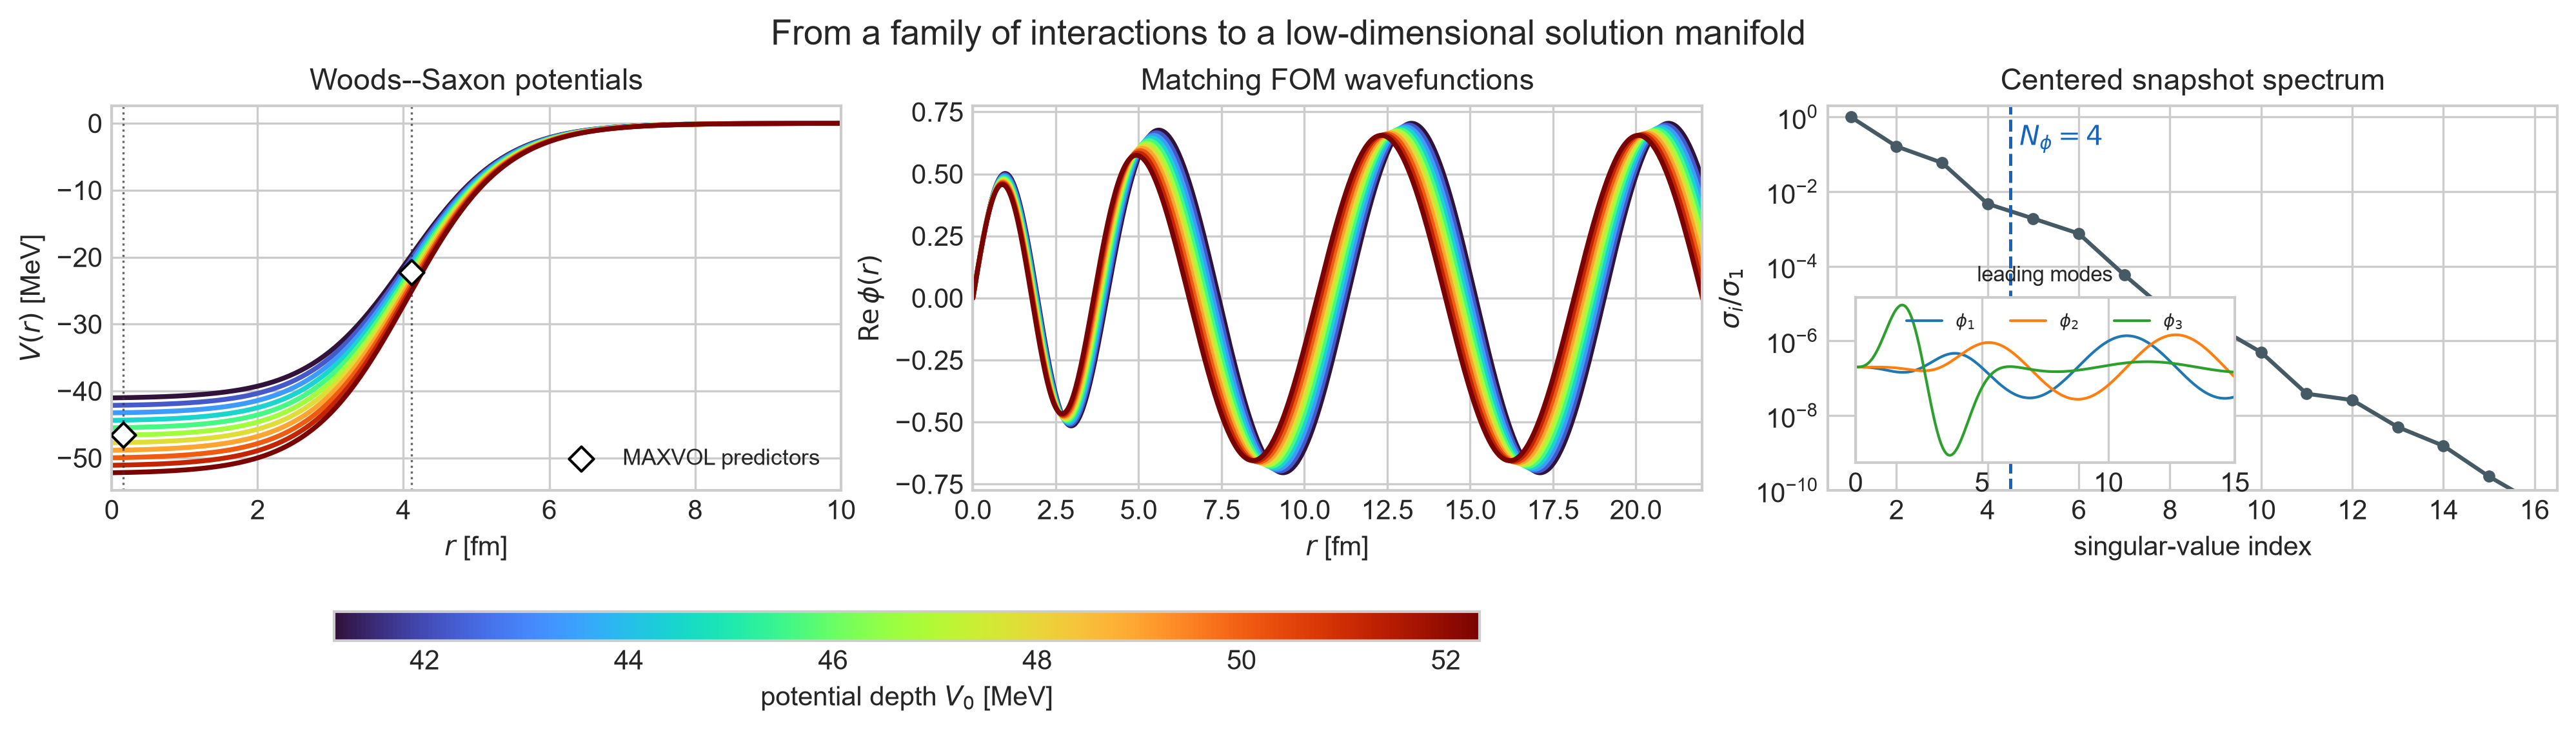

In [4]:
rainbow_depths = np.linspace(train_lower[0], train_upper[0], 11)
rainbow_rows = np.column_stack([
    rainbow_depths,
    np.full_like(rainbow_depths, omega0[1]),
    np.full_like(rainbow_depths, omega0[2]),
])
rainbow_data = problem.generate_training_data(samples_from_rows(rainbow_rows))
rainbow_wave = rainbow_data.wavefunctions[(0, 0.0)]
rainbow_potential = np.asarray([real_woods_saxon(radius, row) for row in rainbow_rows])
depth_norm = plt.Normalize(rainbow_depths.min(), rainbow_depths.max())

fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.65), layout="constrained")

for depth, potential_values in zip(rainbow_depths, rainbow_potential):
    axes[0].plot(radius, potential_values.real, color=RAINBOW(depth_norm(depth)), lw=1.8)
for location in predictor_radii:
    axes[0].axvline(location, color="0.2", lw=0.8, ls=":", alpha=0.75)
central_potential = real_woods_saxon(radius, omega0).real
axes[0].scatter(
    predictor_radii,
    np.interp(predictor_radii, radius, central_potential),
    marker="D", s=42, facecolor="white", edgecolor="black", zorder=5,
    label="MAXVOL predictors",
)
axes[0].set(
    xlim=(0, 10), xlabel=r"$r$ [fm]", ylabel=r"$V(r)$ [MeV]",
    title="Woods--Saxon potentials",
)
axes[0].legend(loc="lower right")

for depth, wave in zip(rainbow_depths, rainbow_wave):
    axes[1].plot(radius, wave.real, color=RAINBOW(depth_norm(depth)), lw=1.8)
axes[1].set(
    xlim=(0, 22), xlabel=r"$r$ [fm]", ylabel=r"$\mathrm{Re}\,\phi(r)$",
    title="Matching FOM wavefunctions",
)

relative_singular = model.basis.singular_values / model.basis.singular_values[0]
indices = np.arange(1, len(relative_singular) + 1)
axes[2].semilogy(indices, relative_singular, "o-", ms=3.5, color="#455A64")
axes[2].axvline(BASIS_SIZE + 0.5, color="#1565C0", ls="--", lw=1.2)
axes[2].set(
    xlabel="singular-value index", ylabel=r"$\sigma_i/\sigma_1$",
    title="Centered snapshot spectrum", xlim=(0.5, 16.5), ylim=(1e-10, 2),
)
axes[2].text(
    BASIS_SIZE + 0.7, 0.6, rf"$N_\phi={BASIS_SIZE}$",
    color="#1565C0", va="top",
)

mode_axis = inset_axes(axes[2], width="52%", height="43%", loc="lower left", borderpad=1.2)
for index in range(min(3, BASIS_SIZE)):
    mode_axis.plot(
        radius, model.basis.vectors[:, index].real,
        lw=1.0, label=rf"$\phi_{{{index+1}}}$",
    )
mode_axis.set_xlim(0, 15)
mode_axis.set_xticks([0, 5, 10, 15])
mode_axis.set_yticks([])
mode_axis.set_title("leading modes", fontsize=8)
mode_axis.legend(fontsize=6.5, ncol=3, loc="upper center")

colorbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=depth_norm, cmap=RAINBOW),
    ax=axes[:2], location="bottom", shrink=0.72, pad=0.11, aspect=40,
)
colorbar.set_label(r"potential depth $V_0$ [MeV]")
fig.suptitle(
    r"From a family of interactions to a low-dimensional solution manifold",
    fontsize=13,
)
save_figure(fig, "figure_01_potential_wavefunction_basis")

## Figure 2: learned coordinate geometry and global held-out error

The top row compares the least-squares projection coordinates with the LROM
and a direct quadratic regression.  Curve color identifies the depth; radius
varies horizontally.  The gray margins are outside the training interval in
radius.  The lower row replaces a single selected wavefunction with global
error maps over the broader two-dimensional evaluation region.  The black
rectangle marks the training box.

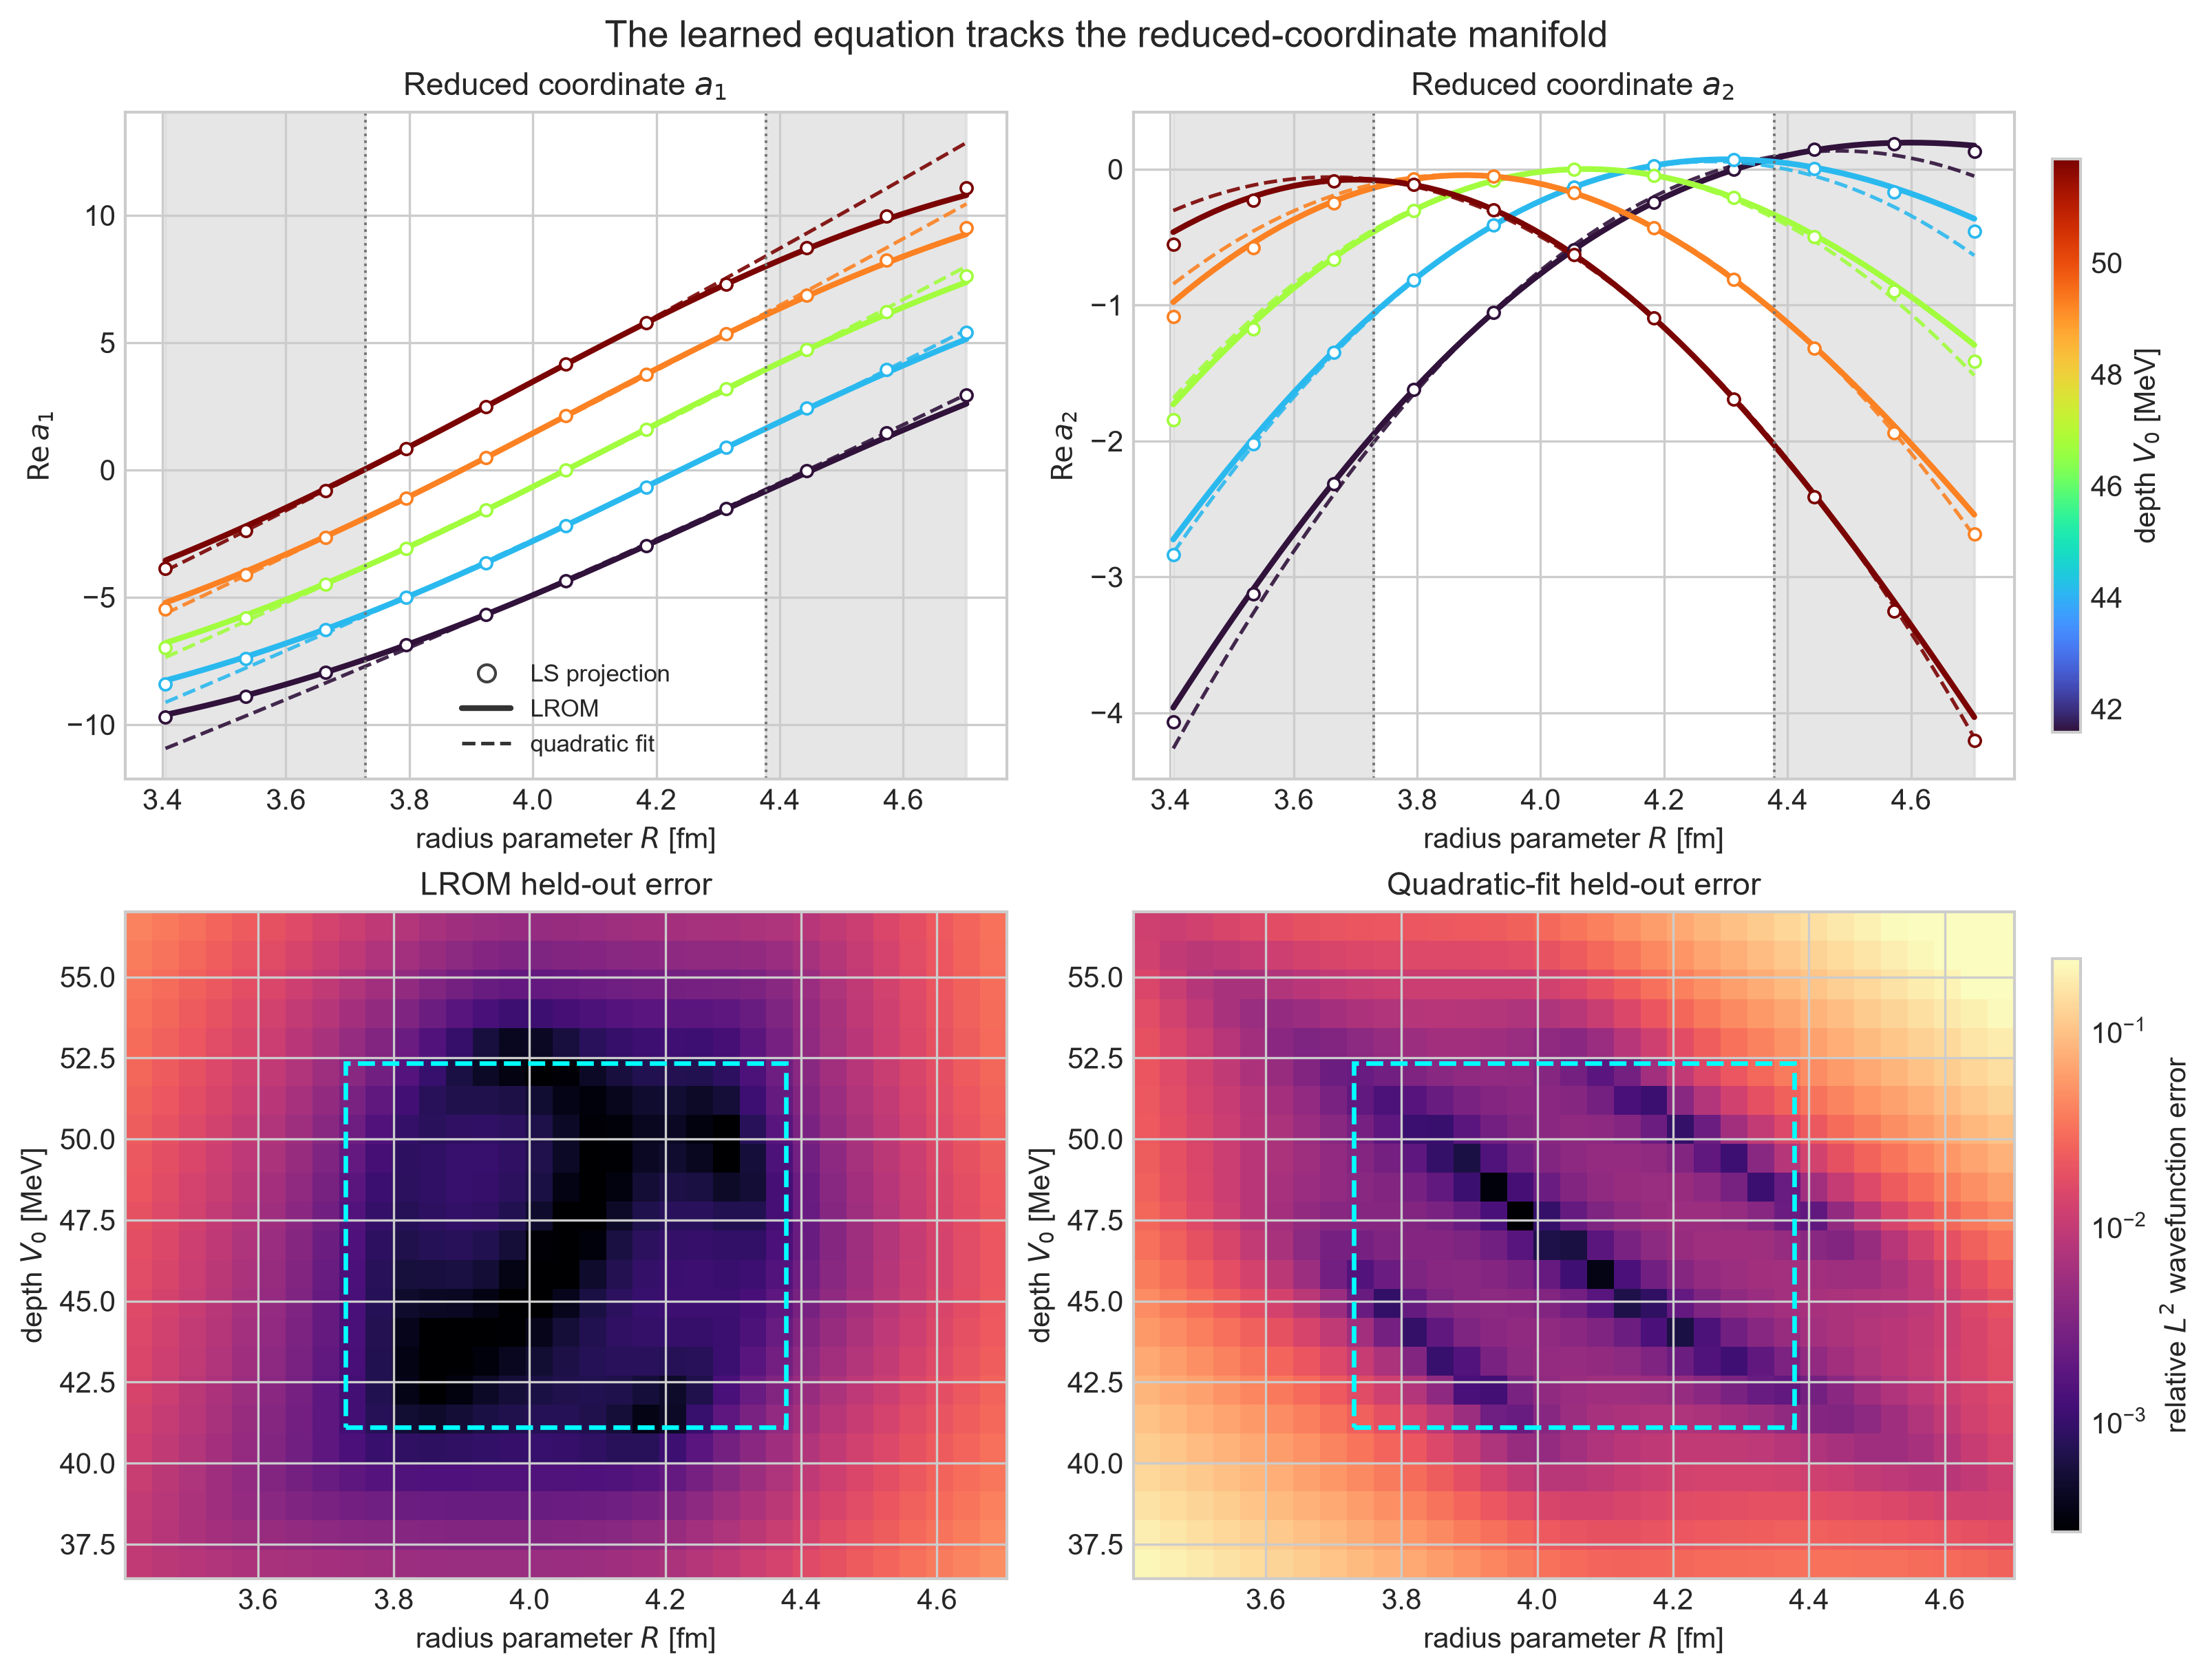

In [5]:
track_shape = (len(track_depths), len(track_radii), BASIS_SIZE)
ls_tracks = ls_track_coordinates.reshape(track_shape)
lrom_tracks = lrom_track_coordinates.reshape(track_shape)
quadratic_tracks = quadratic_track_coordinates.reshape(track_shape)
track_norm = plt.Normalize(track_depths.min(), track_depths.max())

lrom_map_error = relative_l2(lrom_map_wave, map_wave).reshape(len(map_depths), len(map_radii))
quadratic_map_error = relative_l2(quadratic_map_wave, map_wave).reshape(len(map_depths), len(map_radii))
positive_errors = np.concatenate([
    lrom_map_error[lrom_map_error > 0],
    quadratic_map_error[quadratic_map_error > 0],
])
error_norm = LogNorm(
    vmin=max(1e-8, np.percentile(positive_errors, 1)),
    vmax=min(1.0, np.percentile(positive_errors, 99.5)),
)

fig, axes = plt.subplots(2, 2, figsize=(10.6, 8.0), layout="constrained")

for coordinate_index, ax in enumerate(axes[0]):
    for depth_index, depth in enumerate(track_depths):
        color = RAINBOW(track_norm(depth))
        ax.plot(
            track_radii, lrom_tracks[depth_index, :, coordinate_index].real,
            color=color, lw=2.0,
        )
        ax.plot(
            track_radii, quadratic_tracks[depth_index, :, coordinate_index].real,
            color=color, lw=1.25, ls="--", alpha=0.9,
        )
        ax.scatter(
            track_radii[::6], ls_tracks[depth_index, ::6, coordinate_index].real,
            s=17, facecolor="white", edgecolor=color, linewidth=0.9, zorder=4,
        )
    ax.axvspan(track_radii.min(), train_lower[1], color="0.85", alpha=0.65, zorder=0)
    ax.axvspan(train_upper[1], track_radii.max(), color="0.85", alpha=0.65, zorder=0)
    ax.axvline(train_lower[1], color="0.45", ls=":", lw=0.9)
    ax.axvline(train_upper[1], color="0.45", ls=":", lw=0.9)
    ax.set(
        xlabel=r"radius parameter $R$ [fm]",
        ylabel=rf"$\mathrm{{Re}}\,a_{{{coordinate_index+1}}}$",
        title=rf"Reduced coordinate $a_{{{coordinate_index+1}}}$",
    )

method_legend = [
    Line2D([], [], marker="o", ls="none", mfc="white", mec="0.25", label="LS projection"),
    Line2D([], [], color="0.2", lw=2.0, label="LROM"),
    Line2D([], [], color="0.2", lw=1.25, ls="--", label="quadratic fit"),
]
axes[0, 0].legend(handles=method_legend, loc="best")
coordinate_colorbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=track_norm, cmap=RAINBOW),
    ax=axes[0], location="right", shrink=0.86, pad=0.02,
)
coordinate_colorbar.set_label(r"depth $V_0$ [MeV]")

extent = [map_radii.min(), map_radii.max(), map_depths.min(), map_depths.max()]
for ax, values, title in zip(
    axes[1],
    [lrom_map_error, quadratic_map_error],
    ["LROM held-out error", "Quadratic-fit held-out error"],
):
    image = ax.imshow(
        values,
        origin="lower",
        aspect="auto",
        extent=extent,
        cmap="magma",
        norm=error_norm,
        interpolation="nearest",
    )
    rectangle = plt.Rectangle(
        (train_lower[1], train_lower[0]),
        train_upper[1] - train_lower[1],
        train_upper[0] - train_lower[0],
        fill=False, edgecolor="cyan", lw=1.6, ls="--",
    )
    ax.add_patch(rectangle)
    ax.set(
        xlabel=r"radius parameter $R$ [fm]",
        ylabel=r"depth $V_0$ [MeV]",
        title=title,
    )

error_colorbar = fig.colorbar(image, ax=axes[1], location="right", shrink=0.86, pad=0.02)
error_colorbar.set_label(r"relative $L^2$ wavefunction error")
fig.suptitle(
    "The learned equation tracks the reduced-coordinate manifold",
    fontsize=13,
)
save_figure(fig, "figure_02_coordinates_and_error_maps")

In [6]:
ls_map_wave = model.basis.reconstruct(ls_map_coordinates)
ls_map_error = relative_l2(ls_map_wave, map_wave).reshape(len(map_depths), len(map_radii))

inside = (
    (map_rows[:, 0] >= train_lower[0])
    & (map_rows[:, 0] <= train_upper[0])
    & (map_rows[:, 1] >= train_lower[1])
    & (map_rows[:, 1] <= train_upper[1])
).reshape(len(map_depths), len(map_radii))

rows = []
for name, values in [
    ("best in basis (LS)", ls_map_error),
    ("LROM", lrom_map_error),
    ("quadratic coordinate fit", quadratic_map_error),
]:
    for region, mask in [("inside training box", inside), ("outside training box", ~inside)]:
        selected = values[mask]
        rows.append({
            "method": name,
            "region": region,
            "median relative L2": np.median(selected),
            "95th percentile": np.percentile(selected, 95),
            "maximum": np.max(selected),
        })
metrics = pd.DataFrame(rows)
metrics

                     method                region  ...  95th percentile   maximum
0        best in basis (LS)   inside training box  ...         0.001331  0.001768
1        best in basis (LS)  outside training box  ...         0.007891  0.014826
2                      LROM   inside training box  ...         0.001837  0.004333
3                      LROM  outside training box  ...         0.027874  0.047436
4  quadratic coordinate fit   inside training box  ...         0.011138  0.036352
5  quadratic coordinate fit  outside training box  ...         0.159589  0.343394

[6 rows x 5 columns]

## Reading the two figures

- Figure 1 is intentionally conceptual: a family of potentials maps to a
  visibly structured family of solutions, whose centered singular spectrum
  decays rapidly.  MAXVOL turns the interaction into two physically
  interpretable predictors.
- Figure 2 is the quantitative check.  It compares the learned coordinates to
  direct least-squares projections along several parameter slices and reports
  wavefunction errors over the full two-dimensional domain rather than for one
  selected case.
- The quadratic model is a deliberately transparent explicit-regression
  baseline.  The independent ROSE Petrov--Galerkin comparison is deferred to
  the next paper notebook so that this introductory section does not mix
  bases, full-order solvers, and coefficient conventions.

These are candidate paper layouts.  Panel order, parameter ranges, basis size,
and the lower row of Figure 2 are intentionally easy to revise after visual
review.

In [7]:
_matplotlib_config.cleanup()